# Competency 1: First Machine Learning System

### This project uses the UCI Real Estate Valuation dataset to build a regression model that estimates house price per unit area. The estimate is intended to support an agent's initial review and is not a formal appraisal.

## Prepare Dataset Access

This code prepares Python to download the dataset safely from the UCI website. The `os` library lets Python use a setting for the certificate location. The `certifi` library provides trusted security certificates. The `ssl` library creates a secure connection, and `urllib.request` uses that connection when Python contacts the website.

This extra setup was needed because of the certificate configuration on macOS. It allows Python to download the dataset safely, but it does not change the dataset or affect the machine-learning model.

In [1]:
import os
import ssl
import urllib.request
import certifi

os.environ["SSL_CERT_FILE"] = certifi.where()
certificate_context = ssl.create_default_context(cafile=certifi.where())
urllib.request.install_opener(
    urllib.request.build_opener(
        urllib.request.HTTPSHandler(context=certificate_context)
    )
)

## Import Libraries

The project uses pandas to organize data, Matplotlib to create graphs, and scikit-learn to split the data, preprocess the features, train the regression model, and evaluate its predictions.

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn import preprocessing

## Access the Dataset

In [3]:
from ucimlrepo import fetch_ucirepo

dataset = fetch_ucirepo(id=477)
X = dataset.data.features.copy()
y = dataset.data.targets.squeeze()

data = X.copy()
data["house_price_of_unit_area"] = y

print(X.columns)
print(X.shape)

Index(['X1 transaction date', 'X2 house age',
       'X3 distance to the nearest MRT station',
       'X4 number of convenience stores', 'X5 latitude', 'X6 longitude'],
      dtype='str')
(414, 6)


## Exploring the Dataset

In [4]:
print('Rows and Columns:', data.shape)
data.info()
data.describe()
data.isna().sum()
data.head()

Rows and Columns: (414, 7)
<class 'pandas.DataFrame'>
RangeIndex: 414 entries, 0 to 413
Data columns (total 7 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   X1 transaction date                     414 non-null    float64
 1   X2 house age                            414 non-null    float64
 2   X3 distance to the nearest MRT station  414 non-null    float64
 3   X4 number of convenience stores         414 non-null    int64  
 4   X5 latitude                             414 non-null    float64
 5   X6 longitude                            414 non-null    float64
 6   house_price_of_unit_area                414 non-null    float64
dtypes: float64(6), int64(1)
memory usage: 22.8 KB


,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,house_price_of_unit_area
0,2012.917,32.0,84.87882,10,24.98298,121.54024,37.9
1,2012.917,19.5,306.59470,9,24.98034,121.53951,42.2
2,2013.583,13.3,561.98450,5,24.98746,121.54391,47.3
3,2013.500,13.3,561.98450,5,24.98746,121.54391,54.8
4,2012.833,5.0,390.56840,5,24.97937,121.54245,43.1


### Check for duplicate rows

In [5]:
print('Duplicate rows:', data.duplicated().sum())

Duplicate rows: 0


### Check for missing values

In [6]:
data.isna().sum()

X1 transaction date                       0
X2 house age                              0
X3 distance to the nearest MRT station    0
X4 number of convenience stores           0
X5 latitude                               0
X6 longitude                              0
house_price_of_unit_area                  0
dtype: int64

### Check for unsusual values or ranges

In [7]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
X1 transaction date,414.0,2013.148971,0.281967,2012.66700,2012.917000,2013.16700,2013.417000,2013.58300
X2 house age,414.0,17.712560,11.392485,0.00000,9.025000,16.10000,28.150000,43.80000
X3 distance to the nearest MRT station,414.0,1083.885689,1262.109595,23.38284,289.324800,492.23130,1454.279000,6488.02100
X4 number of convenience stores,414.0,4.094203,2.945562,0.00000,1.000000,4.00000,6.000000,10.00000
X5 latitude,414.0,24.969030,0.012410,24.93207,24.963000,24.97110,24.977455,25.01459
X6 longitude,414.0,121.533361,0.015347,121.47353,121.528085,121.53863,121.543305,121.56627
house_price_of_unit_area,414.0,37.980193,13.606488,7.60000,27.700000,38.45000,46.600000,117.50000


The dataset contains 414 property records, 6 input features, and 1 target value. The identifier column was not included because it only identifies each record. The features are numeric, and no missing values or unusual values or ranges were found. The transaction date is stored as a decimal number representing the timing of the transaction, so it will remain numeric. The target is house price per unit area.

## Graph the Data in Scatterplots to see Correlation

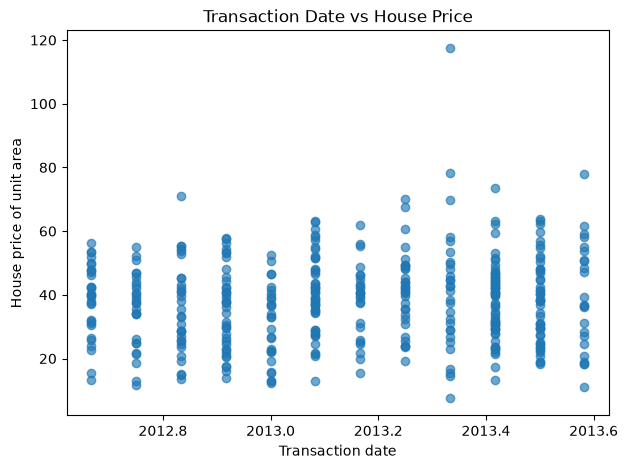

In [8]:
plt.figure(figsize=(7, 5))
plt.scatter(data["X1 transaction date"],
            data["house_price_of_unit_area"],
            alpha=0.65)
plt.xlabel("Transaction date")
plt.ylabel("House price of unit area")
plt.title("Transaction Date vs House Price")
plt.show()

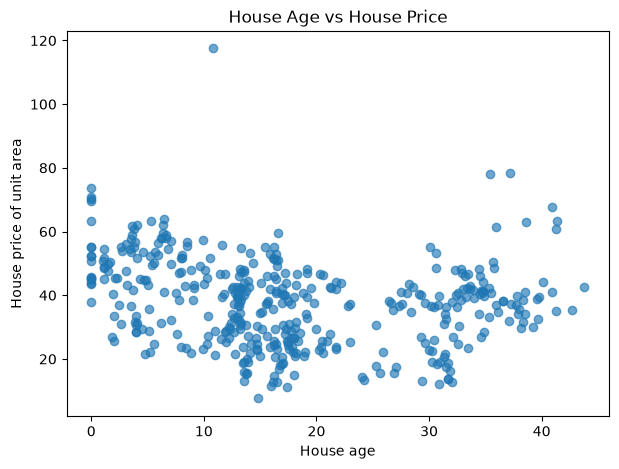

In [9]:
plt.figure(figsize=(7, 5))
plt.scatter(data["X2 house age"],
            data["house_price_of_unit_area"],
            alpha=0.65)
plt.xlabel("House age")
plt.ylabel("House price of unit area")
plt.title("House Age vs House Price")
plt.show()

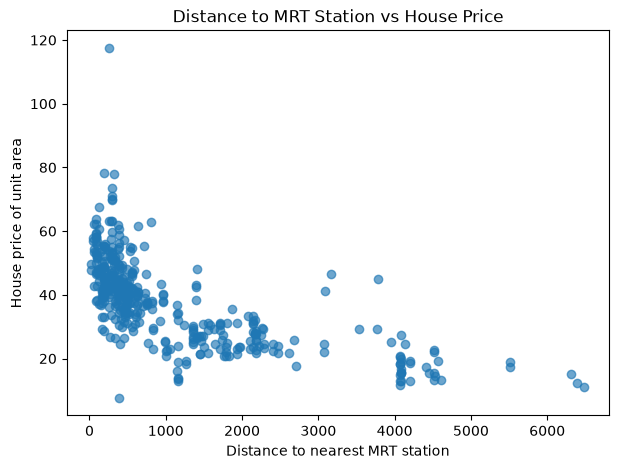

In [10]:
plt.figure(figsize=(7, 5))
plt.scatter(data["X3 distance to the nearest MRT station"],
            data["house_price_of_unit_area"],
            alpha=0.65)
plt.xlabel("Distance to nearest MRT station")
plt.ylabel("House price of unit area")
plt.title("Distance to MRT Station vs House Price")
plt.show()

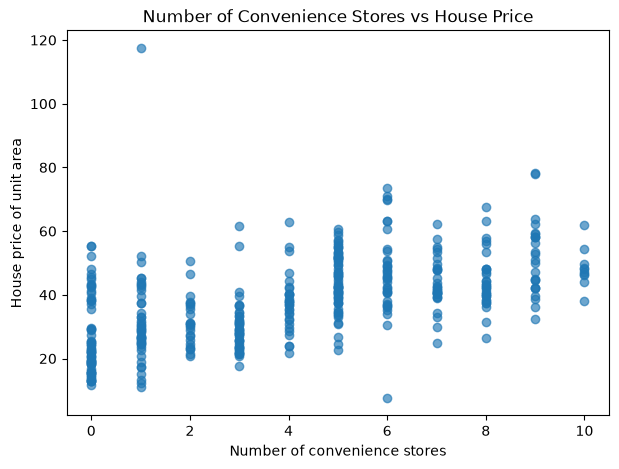

In [11]:
plt.figure(figsize=(7, 5))
plt.scatter(data["X4 number of convenience stores"],
            data["house_price_of_unit_area"],
            alpha=0.65)
plt.xlabel("Number of convenience stores")
plt.ylabel("House price of unit area")
plt.title("Number of Convenience Stores vs House Price")
plt.show()

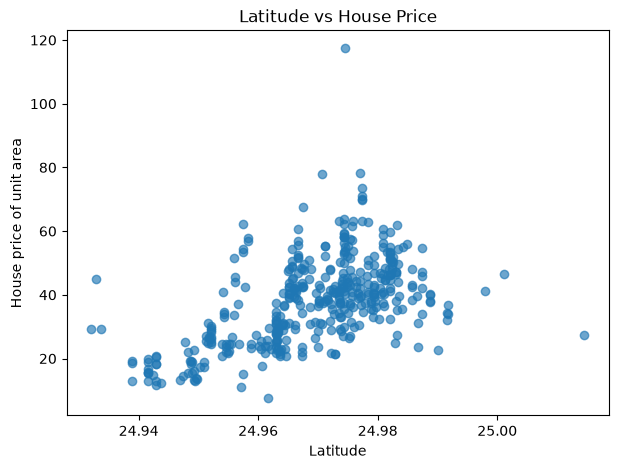

In [12]:
plt.figure(figsize=(7, 5))
plt.scatter(data["X5 latitude"],
            data["house_price_of_unit_area"],
            alpha=0.65)
plt.xlabel("Latitude")
plt.ylabel("House price of unit area")
plt.title("Latitude vs House Price")
plt.show()

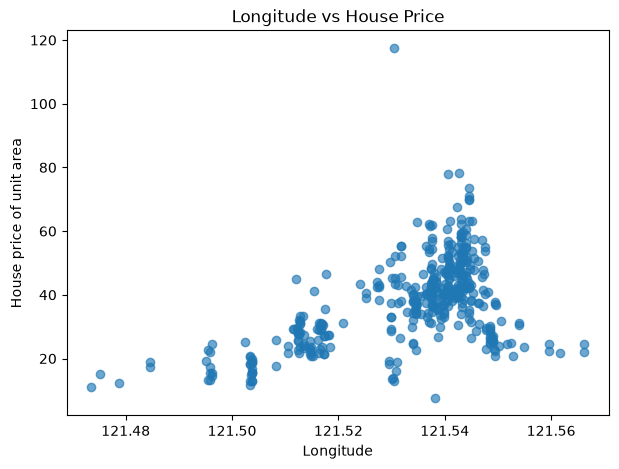

In [13]:
plt.figure(figsize=(7, 5))
plt.scatter(data["X6 longitude"],
            data["house_price_of_unit_area"],
            alpha=0.65)
plt.xlabel("Longitude")
plt.ylabel("House price of unit area")
plt.title("Longitude vs House Price")
plt.show()

In [14]:
correlations = data.corr(numeric_only=True)["house_price_of_unit_area"]
correlations.sort_values()

X3 distance to the nearest MRT station   -0.673613
X2 house age                             -0.210567
X1 transaction date                       0.087491
X6 longitude                              0.523287
X5 latitude                               0.546307
X4 number of convenience stores           0.571005
house_price_of_unit_area                  1.000000
Name: house_price_of_unit_area, dtype: float64

### Correlation Summary

The feature with the strongest relationship to house price per unit area was the distance to the nearest MRT station. Its correlation was negative, meaning that properties farther from an MRT station generally tend to have lower prices per unit area in this dataset. The other features showed weaker relationships.

These correlations describe patterns in this dataset, but correlation does not prove causation. For example, distance from an MRT station may be related to other factors, such as neighborhood location or access to services. The correlations also examine each feature separately, while the regression model considers all six features together.

## Split the Dataset

In [15]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (331, 6)
X_test: (83, 6)
y_train: (331,)
y_test: (83,)


The data was split into training and test sets before preprocessing or modeling decisions were made. 20% of the records were reserved as test data, while the remaining 80% were used for training. The model will learn from the training data, and the test data will later estimate how well it performs on properties it has not seen before. A fixed random state makes the split reproducible.

## Data Preprocessing

All six input features are numeric, so they can be processed using a numeric preprocessing pipeline. The features have different units and ranges, so standardization will place them on comparable scales. The preprocessing will be fit using only the training data so information from the test data does not influence the model. I added `Pipeline` and `preprocessing` from scikit-learn to the Import cell for this step, and then used `preprocessing.StandardScaler()` in the pipeline 

In [16]:
pipeline = Pipeline([
    ("scaler", preprocessing.StandardScaler()), 
    ("model", LinearRegression())
    ])

## Train Regression Model

In [17]:
pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['X1 transaction date','X2 house age', 'X3 distance to the nearest MRT station', 'X4 number of convenience stores','X5 latitude','X6 longitude']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


## Evaluate the model
Using data it did not see during training

In [18]:
predictions = pipeline.predict(X_test)
mae = mean_absolute_error(y_test, predictions)
mse = mean_squared_error(y_test, predictions)
r2 = r2_score(y_test, predictions)

print(f'MAE: {round(mae, 3)}')
print(f'MSE: {round(mse, 3)}')
print(f'R^2 Score: {round(r2, 2)}')

MAE: 5.305
MSE: 53.506
R^2 Score: 0.68


### Interpreting the Results

The model was tested using properties that were kept separate from the training data. This gives a more realistic estimate of how it may perform on a property it has not seen before.

The mean absolute error was **5.305 target units**. In practical terms, the model's estimate was about 5.3 units higher or lower than the actual house price per unit area on average. The mean squared error was **53.506**. This metric gives more weight to larger mistakes, so it helps show when some predictions are much farther from the actual values.

The R-squared score was **0.68**, which means the model explained about 68% of the differences in the test properties' prices. This suggests that the model found useful patterns in the property and location information, but it did not explain every difference in price.

These results make the model useful as a starting point for an agent's initial review. The predictions should not be treated as a formal appraisal because the model can make mistakes, and the dataset represents transactions from one location and time period. A detailed market analysis should still consider current market conditions, property condition, renovations, neighborhood changes, and other information not included in the model.

## Make Predictions for New Properties

The trained pipeline will estimate the house price per unit area for three hypothetical properties. Each property must provide the same six input features used during training. The examples will be kept within plausible ranges observed in the dataset.

In [19]:
new_properties = pd.DataFrame(
    [
        {
            "X1 transaction date": 2013.25,
            "X2 house age": 10.5,
            "X3 distance to the nearest MRT station": 500.0,
            "X4 number of convenience stores": 5,
            "X5 latitude": 24.982,
            "X6 longitude": 121.543
        },
        {
            "X1 transaction date": 2012.75,
            "X2 house age": 15.0,
            "X3 distance to the nearest MRT station": 1000.0,
            "X4 number of convenience stores": 3,
            "X5 latitude": 24.966,
            "X6 longitude": 121.512
        },
        {
            "X1 transaction date": 2013.50,
            "X2 house age": 8.0,
            "X3 distance to the nearest MRT station": 300.0,
            "X4 number of convenience stores": 2,
            "X5 latitude": 24.995,
            "X6 longitude": 121.528
        }
    ],
    index=["Property A", "Property B", "Property C"]
)

In [20]:
new_predictions = pipeline.predict(new_properties).round(2)
print('Estimated house price per unit area:')
print('   Property A:', new_predictions[0])
print('   Property B:', new_predictions[1])
print('   Property C:', new_predictions[2])

Estimated house price per unit area:
   Property A: 46.91
   Property B: 35.66
   Property C: 50.05


The predictions are reported in the dataset's target unit: 10,000 New Taiwan dollars per ping. These are estimated prices per unit area, not total property prices or price changes.

In [21]:
display_results = pd.DataFrame({
    "Transaction date": new_properties["X1 transaction date"],
    "House age": new_properties["X2 house age"],
    "Distance to nearest MRT station": new_properties[
        "X3 distance to the nearest MRT station"
    ],
    "Nearby convenience stores": new_properties[
        "X4 number of convenience stores"
    ],
    "Latitude": new_properties["X5 latitude"],
    "Longitude": new_properties["X6 longitude"],
    "Estimated price per unit area": new_predictions
})

display_results

,Transaction date,House age,Distance to nearest MRT station,Nearby convenience stores,Latitude,Longitude,Estimated price per unit area
Property A,2013.25,10.5,500.0,5,24.982,121.543,46.91
Property B,2012.75,15.0,1000.0,3,24.966,121.512,35.66
Property C,2013.50,8.0,300.0,2,24.995,121.528,50.05


## Actual vs. Predicted Values

This plot compares the actual prices from the test data with the model's predicted prices. Points closer to the diagonal line represent more accurate predictions.

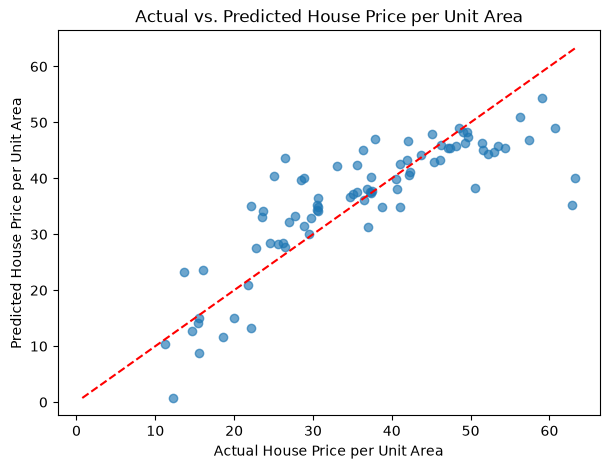

In [22]:
plt.figure(figsize=(7, 5))
plt.scatter(y_test, predictions, alpha=0.65)

low = min(y_test.min(), predictions.min())
high = max(y_test.max(), predictions.max())

plt.plot([low, high], [low, high], color="red", linestyle="--")
plt.xlabel("Actual House Price per Unit Area")
plt.ylabel("Predicted House Price per Unit Area")
plt.title("Actual vs. Predicted House Price per Unit Area")
plt.show()

## Conclusion

The model produced three estimated house prices per unit area for the example properties. Property A was estimated at approximately 46.91, Property B at 35.66, and Property C at 50.05 in the dataset's unit of 10,000 New Taiwan dollars per ping. These results show how the model can provide a quick starting estimate when an agent has basic property and location information.

The final test plot compares the model's estimates with the actual prices for properties that were not used during training. Predictions closer to the diagonal line are closer to the actual prices. The model had a mean absolute error of about 5.3 units and an R-squared score of 0.68, so it found useful patterns but did not predict every price exactly.

This system is intended to support an agent's initial review, not replace a detailed market analysis or formal appraisal. The model was trained on transactions from one location and period, so it may not perform the same way in another market or at another time. Current market conditions, property condition, renovations, neighborhood changes, and other details should also be considered before making a real estate decision.